# 03. Finalize, save and load

The champion's path to production: refit on the allowed history, forecast, a single evaluation on the sealed test, persistence with a manifest and reloading in another process.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc2


## 1. Experiment and champion

In [2]:
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

y = get_data("synthetic_daily")
exp = AutoHybridExperiment(fh=14, session_id=42).fit(y)
best = exp.compare_models().best

## 2. Finalize

The structure and the hyperparameters stay frozen; only the coefficients are refitted on the history before the test, and the corrector's residuals are regenerated with the same policy.

In [3]:
final = exp.finalize_model(best)
print("structure:", final.spec)
print("trained up to:", final.training_cutoff)

structure: CandidateSpec(family='tree', strategy='standalone', base=ModelSpec(name='random_forest', params_json='{"lags":7}'), corrector=None, window_size=None, alpha=None, residual_source=None, variant='A', members=(), options_json='{}', components=(), candidate_id='1f8d8f124a8728e54358f736b6cef1744bd8df58ebf5b13403a2dd2723163f06')
trained up to: 2025-12-16 00:00:00


## 3. Forecast

In [4]:
forecast = exp.predict_model(final)
forecast.predictions

,series_id,origin,horizon,y_pred
timestamp,,,,
2025-12-17,__single__,2025-12-16,1,73.378733
2025-12-18,__single__,2025-12-16,2,71.898770
2025-12-19,__single__,2025-12-16,3,70.122112
2025-12-20,__single__,2025-12-16,4,68.294473
2025-12-21,__single__,2025-12-16,5,68.671440
2025-12-22,__single__,2025-12-16,6,70.818109
2025-12-23,__single__,2025-12-16,7,73.083289
2025-12-24,__single__,2025-12-16,8,73.790339
2025-12-25,__single__,2025-12-16,9,72.286542


## 4. Evaluate on the sealed test

Only one call per finalized model. Using this number to go back and change the configuration would turn the test into validation.

In [5]:
external = exp.evaluate_external(final)
external.metrics

,MASE,MAE,RMSE,sMAPE
model,,,,
random_forest(lags=7),0.704631,1.103425,1.273037,0.015608


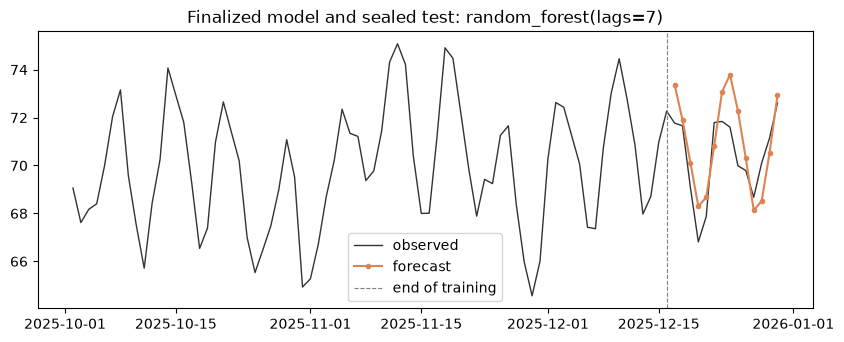

In [6]:
import matplotlib.pyplot as plt

recent = y.iloc[-90:]
predictions = external.predictions
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(recent.index, recent.to_numpy(), color="#333333", linewidth=1, label="observed")
ax.plot(
    predictions.index, predictions["y_pred"], "o-", color="#DD8452", markersize=3, label="forecast"
)
ax.axvline(
    final.training_cutoff, color="gray", linestyle="--", linewidth=0.8, label="end of training"
)
ax.set_title(f"Finalized model and sealed test: {final.spec.label}")
ax.legend()
plt.show()

## 5. Save and load

`save_model` writes the model with a manifest (versions, hashes, `training_cutoff`). `load_model` reads the manifest without executing anything; `trusted=True` declares trust in the file and allows deserialization. Never use `trusted=True` with artifacts of unknown origin.

In [7]:
from pathlib import Path

from autohybts import load_model, save_model

path = save_model(final, Path("artifacts") / "champion")
restored = load_model(path, trusted=True)
restored.manifest

{'model_id': '89f3c27029c3f5f7b85c9555b47a6096c87e2b9ca06ae023b825a277ae476d2b',
 'spec': {'candidate_id': '1f8d8f124a8728e54358f736b6cef1744bd8df58ebf5b13403a2dd2723163f06',
  'label': 'random_forest(lags=7)',
  'describe': {'family': 'tree',
   'strategy': 'standalone',
   'base': {'name': 'random_forest', 'params': {'lags': 7}},
   'corrector': None,
   'window_size': None,
   'alpha': None,
   'residual_source': None,
   'variant': 'A'}},
 'training_cutoff': '2025-12-16 00:00:00',
 'series_id': '__single__',
 'frequency': 'D',
 'n_observations': 716,
 'history_fingerprint': '82900104735217070dc3caa1b8f4585519eb917c4d46a371f691b45e59e54b0a',
 'plan_fingerprint': '31e3290aeac1df36259d888e6839bdaa9aed875ccb42256b8c7683dab7eee0df',
 'seed': 251114467,
 'experiment': {'fh': 14,
  'session_id': 42,
  'fold': 'auto',
  'fold_strategy': 'expanding',
  'window_size': None,
  'seasonal_period': None,
  'test_size': None,
  'profile': 'standard',
  'variant': 'A',
  'budget': 'small',
  'max_

In [8]:
again = exp.predict_model(restored)
(again.predictions["y_pred"] - forecast.predictions["y_pred"]).abs().max()

np.float64(0.0)

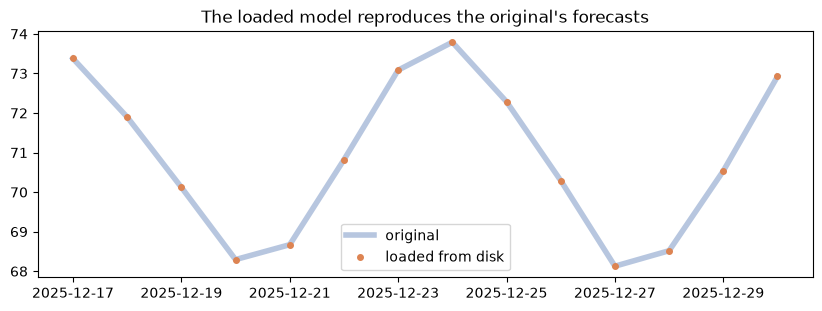

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(
    forecast.predictions.index,
    forecast.predictions["y_pred"],
    color="#4C72B0",
    linewidth=4,
    alpha=0.4,
    label="original",
)
ax.plot(
    again.predictions.index,
    again.predictions["y_pred"],
    "o",
    color="#DD8452",
    markersize=4,
    label="loaded from disk",
)
ax.set_title("The loaded model reproduces the original's forecasts")
ax.legend()
plt.show()

## 6. Operational forecasting

To forecast dates that have not happened yet, use `test_size=0`: there is no sealed test, and the finalized model is refitted on the whole history.

In [10]:
production = AutoHybridExperiment(fh=14, session_id=42, test_size=0).fit(y)
model = production.finalize_model(production.compare_models().best)
model.predict(fh=14)

,series_id,origin,horizon,y_pred
timestamp,,,,
2025-12-31,__single__,2025-12-30,1,73.104426
2026-01-01,__single__,2025-12-30,2,71.504198
2026-01-02,__single__,2025-12-30,3,69.037189
2026-01-03,__single__,2025-12-30,4,67.581331
2026-01-04,__single__,2025-12-30,5,68.252915
2026-01-05,__single__,2025-12-30,6,70.566708
2026-01-06,__single__,2025-12-30,7,72.801684
2026-01-07,__single__,2025-12-30,8,73.296713
2026-01-08,__single__,2025-12-30,9,71.700737


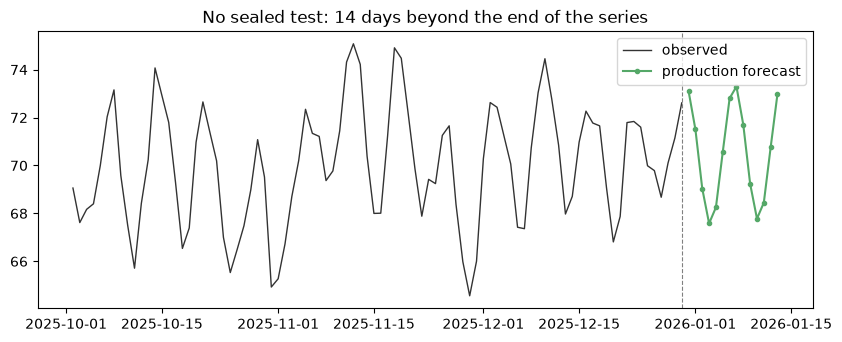

In [11]:
future = model.predict(fh=14)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(y.index[-90:], y.to_numpy()[-90:], color="#333333", linewidth=1, label="observed")
ax.plot(
    future.index, future["y_pred"], "o-", color="#55A868", markersize=3, label="production forecast"
)
ax.axvline(y.index[-1], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("No sealed test: 14 days beyond the end of the series")
ax.legend()
plt.show()